In [ ]:
import cv2
import numpy as np
import urllib.request
import os
import subprocess

#Verify GPU allocation in Colab
gpu_info = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True)
if gpu_info.returncode == 0:
    print(f"GPU detected: {gpu_info.stdout.strip()}")
else:
    print("WARNING: No GPU detected. Please go to Runtime -> Change runtime type -> Select T4 GPU.")

#Download identical sample test image
image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?w=1600&q=80"
sample_file = "base_sample.jpg"

if not os.path.exists(sample_file):
    print("Downloading sample test image...")
    urllib.request.urlretrieve(image_url, sample_file)

base_img = cv2.imread(sample_file, cv2.IMREAD_GRAYSCALE)

# Generate Small, Medium, Large test datasets
resolutions = {
    "Small": (1920, 1080),
    "Medium": (3840, 2160),
    "Large": (7680, 4320)
}

print("\nPreparing input datasets:")
for name, (w, h) in resolutions.items():
    resized = cv2.resize(base_img, (w, h), interpolation=cv2.INTER_CUBIC)
    bin_path = f"input_{name.lower()}.bin"
    resized.tofile(bin_path)
    file_size_mb = os.path.getsize(bin_path) / (1024 * 1024)
    print(f" • {name:6s} ({w}x{h}) -> {bin_path} ({file_size_mb:.2f} MB)")

GPU detected: Tesla T4, 15360 MiB

Preparing input datasets:
 • Small  (1920x1080) -> input_small.bin (1.98 MB)
 • Medium (3840x2160) -> input_medium.bin (7.91 MB)
 • Large  (7680x4320) -> input_large.bin (31.64 MB)


In [ ]:
%%writefile cuda_sharpen.cu
#include <iostream>
#include <vector>
#include <fstream>
#include <string>
#include <algorithm>
#include <cuda_runtime.h>

#define KERNEL_SIZE 3
#define KERNEL_RADIUS 1

#define CHECK_CUDA(call) \
    do { \
        cudaError_t err = call; \
        if (err != cudaSuccess) { \
            std::cerr << "CUDA Error: " << cudaGetErrorString(err) \
                      << " at line " << __LINE__ << std::endl; \
            return 1; \
        } \
    } while (0)

// Standard 3x3 sharpening mask (stored in CUDA constant memory)
__constant__ int d_kernel[3][3] = {
    { 0, -1,  0},
    {-1,  5, -1},
    { 0, -1,  0}
};

// Basic 2D Convolution Kernel (One thread per output pixel)
__global__ void sharpen_kernel(const unsigned char* input, unsigned char* output, int width, int height) {
    int c = blockIdx.x * blockDim.x + threadIdx.x;
    int r = blockIdx.y * blockDim.y + threadIdx.y;

    if (r < height && c < width) {
        int sum = 0;

        for (int kr = -KERNEL_RADIUS; kr <= KERNEL_RADIUS; ++kr) {
            for (int kc = -KERNEL_RADIUS; kc <= KERNEL_RADIUS; ++kc) {
                int nr = r + kr;
                int nc = c + kc;

                // Zero-padding boundary condition matching sequential baseline
                if (nr >= 0 && nr < height && nc >= 0 && nc < width) {
                    sum += (int)input[nr * width + nc] * d_kernel[kr + KERNEL_RADIUS][kc + KERNEL_RADIUS];
                }
            }
        }

        // Clamp to [0, 255]
        output[r * width + c] = (unsigned char)min(255, max(0, sum));
    }
}

int main(int argc, char* argv[]) {
    if (argc < 5) {
        std::cerr << "Usage: " << argv[0] << " <input.bin> <output.bin> <width> <height>\n";
        return 1;
    }

    std::string input_path = argv[1];
    std::string output_path = argv[2];
    int width = std::stoi(argv[3]);
    int height = std::stoi(argv[4]);
    size_t num_pixels = static_cast<size_t>(width) * height;

    // Host memory allocation
    std::vector<unsigned char> h_input(num_pixels);
    std::vector<unsigned char> h_output(num_pixels);

    // Read binary image
    std::ifstream in_file(input_path, std::ios::binary);
    if (!in_file) {
        std::cerr << "Error opening input file: " << input_path << "\n";
        return 1;
    }
    in_file.read(reinterpret_cast<char*>(h_input.data()), num_pixels);
    in_file.close();

    // Device memory allocation
    unsigned char *d_input = nullptr, *d_output = nullptr;
    CHECK_CUDA(cudaMalloc((void**)&d_input, num_pixels * sizeof(unsigned char)));
    CHECK_CUDA(cudaMalloc((void**)&d_output, num_pixels * sizeof(unsigned char)));

    // CUDA timing events
    cudaEvent_t total_start, total_stop, kernel_start, kernel_stop;
    CHECK_CUDA(cudaEventCreate(&total_start));
    CHECK_CUDA(cudaEventCreate(&total_stop));
    CHECK_CUDA(cudaEventCreate(&kernel_start));
    CHECK_CUDA(cudaEventCreate(&kernel_stop));

    // Start Total Time (includes data transfer)
    CHECK_CUDA(cudaEventRecord(total_start, 0));

    // 1. Host -> Device transfer
    CHECK_CUDA(cudaMemcpy(d_input, h_input.data(), num_pixels * sizeof(unsigned char), cudaMemcpyHostToDevice));

    // 2. Configure 2D thread grid & block
    dim3 block_dim(16, 16);
    dim3 grid_dim((width + block_dim.x - 1) / block_dim.x,
                  (height + block_dim.y - 1) / block_dim.y);

    // Start Kernel Time
    CHECK_CUDA(cudaEventRecord(kernel_start, 0));
    sharpen_kernel<<<grid_dim, block_dim>>>(d_input, d_output, width, height);
    CHECK_CUDA(cudaGetLastError());
    CHECK_CUDA(cudaEventRecord(kernel_stop, 0));

    // 3. Device -> Host transfer
    CHECK_CUDA(cudaMemcpy(h_output.data(), d_output, num_pixels * sizeof(unsigned char), cudaMemcpyDeviceToHost));

    // Stop Total Time
    CHECK_CUDA(cudaEventRecord(total_stop, 0));
    CHECK_CUDA(cudaEventSynchronize(total_stop));
    CHECK_CUDA(cudaEventSynchronize(kernel_stop));

    // Elapsed time calculation
    float kernel_ms = 0.0f, total_ms = 0.0f;
    CHECK_CUDA(cudaEventElapsedTime(&kernel_ms, kernel_start, kernel_stop));
    CHECK_CUDA(cudaEventElapsedTime(&total_ms, total_start, total_stop));

    // Print format: kernel_ms,total_ms
    std::cout << kernel_ms << "," << total_ms;

    // Save processed binary
    std::ofstream out_file(output_path, std::ios::binary);
    out_file.write(reinterpret_cast<const char*>(h_output.data()), num_pixels);
    out_file.close();

    CHECK_CUDA(cudaFree(d_input));
    CHECK_CUDA(cudaFree(d_output));
    CHECK_CUDA(cudaEventDestroy(total_start));
    CHECK_CUDA(cudaEventDestroy(total_stop));
    CHECK_CUDA(cudaEventDestroy(kernel_start));
    CHECK_CUDA(cudaEventDestroy(kernel_stop));

    return 0;
}


Writing cuda_sharpen.cu


In [ ]:
!nvcc -O3 -arch=sm_75 -Wno-deprecated-gpu-targets cuda_sharpen.cu -o cuda_sharpen
print("CUDA compilation complete.")


CUDA compilation complete.


In [ ]:
import subprocess
import numpy as np

configs = [
    ("Small",  1920, 1080, "input_small.bin",  "output_cuda_small.bin"),
    ("Medium", 3840, 2160, "input_medium.bin", "output_cuda_medium.bin"),
    ("Large",  7680, 4320, "input_large.bin",  "output_cuda_large.bin")
]

#Warm-up GPU to eliminate CUDA driver init latency
print("Warming up GPU...")
subprocess.run(["./cuda_sharpen", "input_small.bin", "output_cuda_small.bin", "1920", "1080"], capture_output=True)

NUM_RUNS = 5
cuda_results = {}

print("=" * 78)
print(f"{'Category':<10} | {'Resolution':<12} | {'Kernel Time (ms)':<18} | {'Total Time (ms)':<18} | {'Runs'}")
print("=" * 78)

for category, w, h, in_file, out_file in configs:
    kernel_times = []
    total_times = []

    for _ in range(NUM_RUNS):
        cmd = ["./cuda_sharpen", in_file, out_file, str(w), str(h)]
        result = subprocess.run(cmd, capture_output=True, text=True)

        if result.returncode == 0:
            k_ms, t_ms = map(float, result.stdout.strip().split(","))
            kernel_times.append(k_ms)
            total_times.append(t_ms)

    avg_k = float(np.mean(kernel_times))
    avg_t = float(np.mean(total_times))
    cuda_results[category] = {"kernel_ms": avg_k, "total_ms": avg_t}

    print(f"{category:<10} | {f'{w}x{h}':<12} | {avg_k:<18.2f} | {avg_t:<18.2f} | {NUM_RUNS}")

print("=" * 78)

Warming up GPU...
Category   | Resolution   | Kernel Time (ms)   | Total Time (ms)    | Runs
Small      | 1920x1080    | 0.21               | 1.42               | 5
Medium     | 3840x2160    | 0.42               | 4.35               | 5
Large      | 7680x4320    | 1.43               | 18.80              | 5


1. SEQUENTIAL REFERENCE GENERATION & NUMERICAL VERIFICATION
Dataset    | Resolution   | Max Absolute Diff    | Status
------------------------------------------------------------------------------
Small      | 1920x1080    | 0 (mean: 0.0000)     | MATCH [PASS]
Medium     | 3840x2160    | 0 (mean: 0.0000)     | MATCH [PASS]
Large      | 7680x4320    | 0 (mean: 0.0000)     | MATCH [PASS]


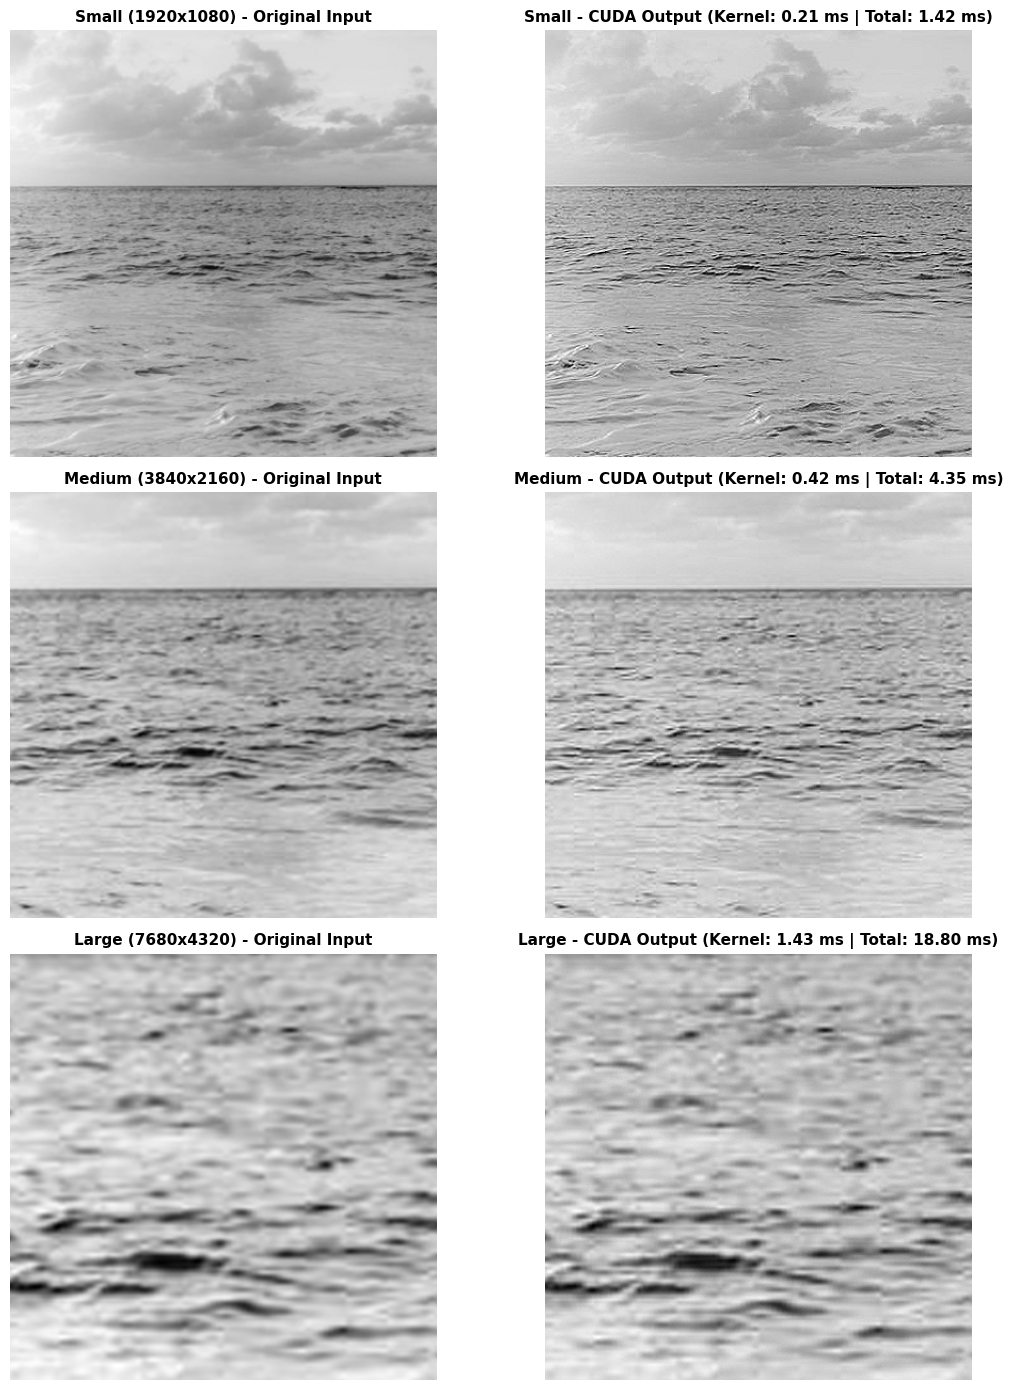

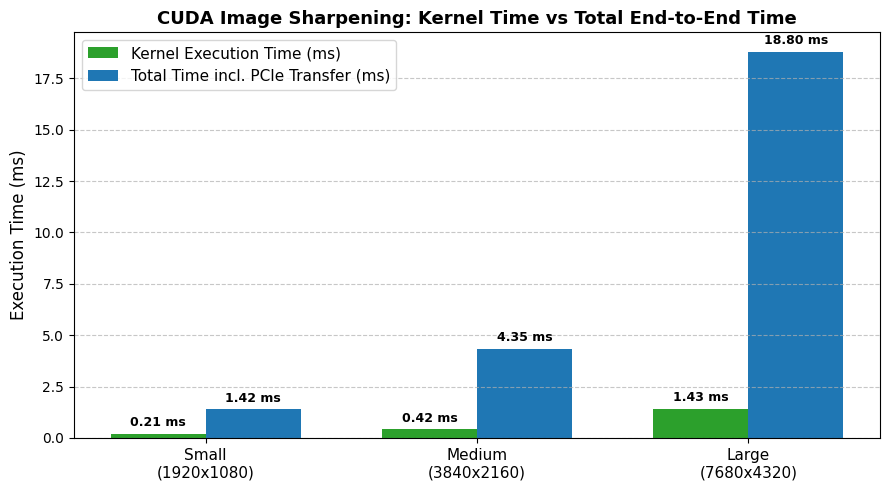

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import subprocess

# Generate Sequential Baseline references directly if missing (ensures 100% self-contained execution in Colab)
print("=" * 78)
print("1. SEQUENTIAL REFERENCE GENERATION & NUMERICAL VERIFICATION")
print("=" * 78)

# Compile sequential baseline C++ helper if needed
seq_cpp_code = '''
#include <iostream>
#include <vector>
#include <fstream>
#include <algorithm>

const int KERNEL[3][3] = {
    { 0, -1,  0},
    {-1,  5, -1},
    { 0, -1,  0}
};

int main(int argc, char* argv[]) {
    if (argc < 5) return 1;
    std::string in_path = argv[1];
    std::string out_path = argv[2];
    int width = std::stoi(argv[3]);
    int height = std::stoi(argv[4]);
    size_t num_pixels = (size_t)width * height;
    std::vector<unsigned char> input(num_pixels), output(num_pixels);

    std::ifstream in_file(in_path, std::ios::binary);
    in_file.read((char*)input.data(), num_pixels);
    in_file.close();

    for (int r = 0; r < height; ++r) {
        for (int c = 0; c < width; ++c) {
            int sum = 0;
            for (int kr = -1; kr <= 1; ++kr) {
                for (int kc = -1; kc <= 1; ++kc) {
                    int nr = r + kr, nc = c + kc;
                    if (nr >= 0 && nr < height && nc >= 0 && nc < width) {
                        sum += input[nr * width + nc] * KERNEL[kr + 1][kc + 1];
                    }
                }
            }
            output[r * width + c] = (unsigned char)std::max(0, std::min(255, sum));
        }
    }
    std::ofstream out_file(out_path, std::ios::binary);
    out_file.write((const char*)output.data(), num_pixels);
    out_file.close();
    return 0;
}
'''

if not os.path.exists("seq_helper"):
    with open("seq_helper.cpp", "w") as f:
        f.write(seq_cpp_code)
    subprocess.run(["g++", "-O3", "seq_helper.cpp", "-o", "seq_helper"])

print(f"{'Dataset':<10} | {'Resolution':<12} | {'Max Absolute Diff':<20} | {'Status'}")
print("-" * 78)

for category, w, h, in_file, out_file in configs:
    seq_file = in_file.replace("input_", "output_")

    # If sequential output doesn't exist, generate it using the reference sequential implementation
    if not os.path.exists(seq_file):
        subprocess.run(["./seq_helper", in_file, seq_file, str(w), str(h)])

    seq_data = np.fromfile(seq_file, dtype=np.uint8)
    cuda_data = np.fromfile(out_file, dtype=np.uint8)

    diff = np.abs(seq_data.astype(int) - cuda_data.astype(int))
    max_diff = int(np.max(diff))
    mean_diff = float(np.mean(diff))
    match = np.array_equal(seq_data, cuda_data)

    status_str = "MATCH [PASS]" if match else "MISMATCH [FAIL]"
    print(f"{category:<10} | {f'{w}x{h}':<12} | {f'{max_diff} (mean: {mean_diff:.4f})':<20} | {status_str}")

print("=" * 78)

# 2. Visual Comparison of Results (Center Crops)
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
plt.subplots_adjust(hspace=0.25)

for idx, (category, w, h, in_file, out_file) in enumerate(configs):
    img_before = np.fromfile(in_file, dtype=np.uint8).reshape((h, w))
    img_after = np.fromfile(out_file, dtype=np.uint8).reshape((h, w))

    cy, cx = h // 2, w // 2
    crop_before = img_before[cy-200:cy+200, cx-200:cx+200]
    crop_after = img_after[cy-200:cy+200, cx-200:cx+200]

    k_ms = cuda_results[category]['kernel_ms']
    t_ms = cuda_results[category]['total_ms']

    axes[idx, 0].imshow(crop_before, cmap='gray')
    axes[idx, 0].set_title(f"{category} ({w}x{h}) - Original Input", fontsize=11, fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(crop_after, cmap='gray')
    axes[idx, 1].set_title(f"{category} - CUDA Output (Kernel: {k_ms:.2f} ms | Total: {t_ms:.2f} ms)", fontsize=11, fontweight='bold')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

# 3. Performance Breakdown Chart (Kernel vs Transfer Overhead)
labels = [c[0] for c in configs]
kernel_times = [cuda_results[c[0]]['kernel_ms'] for c in configs]
total_times = [cuda_results[c[0]]['total_ms'] for c in configs]
transfer_times = [t - k for t, k in zip(total_times, kernel_times)]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, kernel_times, width, label='Kernel Execution Time (ms)', color='#2ca02c')
rects2 = ax.bar(x + width/2, total_times, width, label='Total Time incl. PCIe Transfer (ms)', color='#1f77b4')

ax.set_ylabel('Execution Time (ms)', fontsize=12)
ax.set_title('CUDA Image Sharpening: Kernel Time vs Total End-to-End Time', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f"{c[0]}\n({c[1]}x{c[2]})" for c in configs], fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.2f} ms',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.2f} ms',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


#B.1 Profiling GPU version

In [ ]:
!which ncu || true
!ncu --version || true

/usr/local/cuda/bin/ncu
NVIDIA (R) Nsight Compute Command Line Profiler
Copyright (c) 2018-2025 NVIDIA Corporation
Version 2025.3.1.0 (build 36398880) (public-release)


In [ ]:
!nvcc -O3 -arch=sm_75 -Wno-deprecated-gpu-targets cuda_sharpen.cu -o cuda_sharpen

In [ ]:
!ls -lh cuda_sharpen

-rwxr-xr-x 1 root root 976K Oct  6 19:14 cuda_sharpen


In [ ]:
!./cuda_sharpen input_large.bin out_prof.bin 7680 4320

1.5504,15.869

where:
- first number = kernel time in ms
- second number = total CUDA time in ms

In [ ]:
!ncu --version

NVIDIA (R) Nsight Compute Command Line Profiler
Copyright (c) 2018-2025 NVIDIA Corporation
Version 2025.3.1.0 (build 36398880) (public-release)


In [ ]:
!ncu --set basic ./cuda_sharpen input_large.bin out_prof.bin 7680 4320

==PROF== Connected to process 2721 (/content/cuda_sharpen)
==PROF== Profiling "sharpen_kernel" - 0: 0%....50%....100% - 9 passes
2181.28,2196.26==PROF== Disconnected from process 2721
[2721] cuda_sharpen@127.0.0.1
  sharpen_kernel(const unsigned char *, unsigned char *, int, int) (480, 270, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         5.00
    SM Frequency                    Mhz       584.99
    Elapsed Cycles                cycle    1,248,226
    Memory Throughput                 %        49.84
    DRAM Throughput                   %        24.93
    Duration                         ms         2.13
    L1/TEX Cache Throughput           %        95.24
    L2 Cache Throughput               %        14.47
    SM Active Cycles        

In [ ]:
!ncu --set full ./cuda_sharpen input_large.bin out_prof.bin 7680 4320

==PROF== Connected to process 4217 (/content/cuda_sharpen)
==PROF== Profiling "sharpen_kernel" - 0: 0%....50%....100% - 33 passes
7226.18,7242.67==PROF== Disconnected from process 4217
[4217] cuda_sharpen@127.0.0.1
  sharpen_kernel(const unsigned char *, unsigned char *, int, int) (480, 270, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.99
    SM Frequency                    Mhz       584.99
    Elapsed Cycles                cycle    1,248,683
    Memory Throughput                 %        49.82
    DRAM Throughput                   %        24.92
    Duration                         ms         2.13
    L1/TEX Cache Throughput           %        95.23
    L2 Cache Throughput               %        14.46
    SM Active Cycles       

In [ ]:
!ncu --query-metrics | grep -Ei "global.*(load|store)|load.*efficiency|store.*efficiency" | head -50

l1tex__data_bank_conflicts_pipe_lsu_mem_global_op_ld                        Counter                         # of data bank conflicts generated by global loads                    
l1tex__data_bank_conflicts_pipe_lsu_mem_global_op_st                        Counter                         # of data bank conflicts generated by global stores                   
l1tex__m_l1tex2xbar_write_bytes_mem_lg_op_st                                Counter         byte            # of bytes written to L2 for local/global stores                      
l1tex__m_l1tex2xbar_write_sectors_mem_lg_op_st                              Counter         sector          # of sectors written to L2 for local/global stores                    
l1tex__m_xbar2l1tex_read_bytes_mem_lg_op_ld                                 Counter         byte            # of bytes read from L2 into L1TEX M-Stage for local/global loads     
l1tex__m_xbar2l1tex_read_sectors_mem_lg_op_ld                               Counter         sector       

In [ ]:
!ncu --metrics smsp__sass_average_data_bytes_per_sector_mem_global_op_ld,smsp__sass_average_data_bytes_per_sector_mem_global_op_st,sm__sass_data_bytes_mem_global_op_ld,sm__sass_data_bytes_mem_global_op_st,sm__sass_l1tex_t_sectors_pipe_lsu_mem_global_op_ld,sm__sass_l1tex_t_sectors_pipe_lsu_mem_global_op_st ./cuda_sharpen input_large.bin out_prof.bin 7680 4320

==PROF== Connected to process 5072 (/content/cuda_sharpen)
==PROF== Profiling "sharpen_kernel" - 0: 0%....50%....100% - 1 pass
1247.4,1262.18==PROF== Disconnected from process 5072
[5072] cuda_sharpen@127.0.0.1
  sharpen_kernel(const unsigned char *, unsigned char *, int, int) (480, 270, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Command line profiler metrics
    ------------------------------------------------------------------ ----------- ------------
    Metric Name                                                        Metric Unit Metric Value
    ------------------------------------------------------------------ ----------- ------------
    sm__sass_data_bytes_mem_global_op_ld.avg                                 Mbyte         7.46
    sm__sass_data_bytes_mem_global_op_ld.max                                 Mbyte         7.51
    sm__sass_data_bytes_mem_global_op_ld.min                                 Mbyte         7.40
    sm__sass_data_bytes_mem_global_op_

In [ ]:
%%bash
ARGS="input_large.bin out_prof.bin 7680 4320"
nvidia-smi --query-gpu=name,driver_version --format=csv
export PATH=$PATH:/usr/local/cuda/bin

echo "=== Nsight Compute attempt ==="
ncu --metrics gpu__time_duration.sum,dram__bytes_read.sum,dram__bytes_write.sum,\
dram__throughput.avg.pct_of_peak_sustained_elapsed,sm__throughput.avg.pct_of_peak_sustained_elapsed,\
sm__warps_active.avg.pct_of_peak_sustained_active ./cuda_sharpen $ARGS 2>&1 | tail -25

echo "=== nvprof attempt ==="
nvprof --print-gpu-summary ./cuda_sharpen $ARGS 2>&1 | tail -15

echo "=== Nsight Systems attempt ==="
nsys profile --stats=true -f true -o cuda_prof ./cuda_sharpen $ARGS 2>&1 | grep -A12 -E "cuda_gpu_kern_sum|cuda_gpu_mem_time_sum" | head -40


name, driver_version
Tesla T4, 580.82.07
=== Nsight Compute attempt ===
==PROF== Connected to process 2010 (/content/cuda_sharpen)
==PROF== Profiling "sharpen_kernel" - 0: 0%....50%....100% - 6 passes
2109.26,2125.5==PROF== Disconnected from process 2010
[2010] cuda_sharpen@127.0.0.1
  sharpen_kernel(const unsigned char *, unsigned char *, int, int) (480, 270, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Command line profiler metrics
    -------------------------------------------------- ----------- ------------
    Metric Name                                        Metric Unit Metric Value
    -------------------------------------------------- ----------- ------------
    dram__bytes_read.sum                                     Mbyte       131.41
    dram__bytes_write.sum                                    Mbyte        38.59
    dram__throughput.avg.pct_of_peak_sustained_elapsed           %        24.92
    gpu__time_duration.sum                                  

In [ ]:
%%writefile cuda_energy.cu
#include <cstdio>
#include <cstdlib>
#include <vector>
#include <fstream>
#include <string>
#include <chrono>
#include <cuda_runtime.h>

__constant__ int d_kernel[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

__global__ void sharpen_kernel(const unsigned char* in, unsigned char* out, int w, int h) {
    int c = blockIdx.x * blockDim.x + threadIdx.x;
    int r = blockIdx.y * blockDim.y + threadIdx.y;
    if (r < h && c < w) {
        int sum = 0;
        for (int kr = -1; kr <= 1; ++kr)
            for (int kc = -1; kc <= 1; ++kc) {
                int nr = r + kr, nc = c + kc;
                if (nr >= 0 && nr < h && nc >= 0 && nc < w)
                    sum += (int)in[nr * w + nc] * d_kernel[kr + 1][kc + 1];
            }
        out[r * w + c] = (unsigned char)min(255, max(0, sum));
    }
}

int main(int argc, char** argv) {
    if (argc < 6) return 1;
    int w = atoi(argv[2]), h = atoi(argv[3]);
    std::string mode = argv[4]; double secs = atof(argv[5]);
    size_t n = (size_t)w * h;
    std::vector<unsigned char> hin(n), hout(n);
    std::ifstream f(argv[1], std::ios::binary);
    f.read((char*)hin.data(), n);

    unsigned char *din, *dout;
    cudaMalloc(&din, n); cudaMalloc(&dout, n);
    cudaMemcpy(din, hin.data(), n, cudaMemcpyHostToDevice);
    dim3 blk(16, 16), grd((w + 15) / 16, (h + 15) / 16);
    sharpen_kernel<<<grd, blk>>>(din, dout, w, h);
    cudaDeviceSynchronize();

    long iters = 0; double el = 0;
    auto t0 = std::chrono::steady_clock::now();
    while (el < secs) {
        for (int k = 0; k < 20; ++k) {
            if (mode == "e2e") cudaMemcpy(din, hin.data(), n, cudaMemcpyHostToDevice);
            sharpen_kernel<<<grd, blk>>>(din, dout, w, h);
            if (mode == "e2e") cudaMemcpy(hout.data(), dout, n, cudaMemcpyDeviceToHost);
        }
        cudaDeviceSynchronize();
        iters += 20;
        el = std::chrono::duration<double>(std::chrono::steady_clock::now() - t0).count();
    }
    printf("ITER,%ld,%.6f,%.6f\n", iters, el, el * 1000.0 / iters);
    return 0;
}


Writing cuda_energy.cu


In [ ]:
%%bash
nvcc -O3 -arch=sm_75 -Wno-deprecated-gpu-targets cuda_energy.cu -o cuda_energy
echo "cuda_energy compiled"


cuda_energy compiled


In [ ]:
import subprocess, threading, time, numpy as np, pandas as pd

class PowerSampler:
    def __init__(self):
        self.samples = []
        self.proc = subprocess.Popen(["nvidia-smi", "--query-gpu=power.draw", "--format=csv,noheader,nounits",
                                      "-lms", "100"], stdout=subprocess.PIPE, text=True)
        threading.Thread(target=self._read, daemon=True).start()
    def _read(self):
        for line in self.proc.stdout:
            try: self.samples.append((time.time(), float(line.strip())))
            except ValueError: pass
    def mean_between(self, a, b):
        v = [p for (t, p) in self.samples if a <= t <= b]
        return float(np.mean(v)) if v else float("nan")
    def stop(self): self.proc.terminate()

sampler = PowerSampler()
time.sleep(1)
i0 = time.time(); time.sleep(5); i1 = time.time()
P_idle = sampler.mean_between(i0, i1)
print(f"Idle T4 board power: {P_idle:.1f} W")

t0 = time.time()
r = subprocess.run(["./cuda_energy", "input_large.bin", "7680", "4320", "e2e", "10"], capture_output=True, text=True)
t1 = time.time()
_, iters, el, ms = r.stdout.strip().split(",")
P = sampler.mean_between(t0 + 1.0, t1 - 0.3)
sampler.stop()

print(f"Total time running: {el} seconds ({iters} iterations)")
print(f"Average board power during run: {P:.1f} W")
print(f"Energy per run: {P * float(ms) / 1000.0:.4f} Joules")


Idle T4 board power: 10.0 W
Total time running: 10.091621 seconds (580 iterations)
Average board power during run: 37.0 W
Energy per run: 0.6431 Joules
